# ON/OFF beam subtraction → MR-KLT → C-KLT

This notebook implements the **literal ON/OFF pipeline**, step by step:

1. **Generate** multi-antenna array (MAA) data — a target signal plus an interferer from another direction;
2. **Beamform** to an **ON** sky position with a ring of **OFF** beams around it;
3. **MR-KLT on the OFF beams** — the interference is the common mode across them;
4. **Reconstruct** the interference waveform found in the OFF beams;
5. **Subtract** that reconstruction from the ON beam;
6. **C-KLT on the cleaned ON beam** to surface the signal of interest.

It is the counterpart of [`ONOFF_Nulling.ipynb`](ONOFF_Nulling.ipynb), which reaches the same goal by nulling at the *covariance* level instead of forming explicit OFF beams.

**Why this simulation.** The array geometry (antenna layout + geometric delays) is reused from `MAA_Simulated`; on top of it we synthesise the antenna cube with a narrowband directional model, because the setigen path only injects sources at the pointing (or delay-free RFI) and here we specifically need an interferer at a **chosen direction** so it can sit inside an OFF beam.

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

from helpers import (
    SimConfig, build_geometry, steering, offset_direction, simulate_cube,
    beamform, beam_response, beam_grid, beam_pattern_2d, ls_subtract,
    process_channel, run_experiment, experiment_report, stress_point,
)
from seti_klt import KLT
from seti_klt.utils.io import SimpleLogger, LogLevel

C_ON, C_RFI, C_OFF, C_CLEAN = "#0072B2", "#D55E00", "#888888", "#009E73"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#888888",
    "xtick.color": "#666666", "ytick.color": "#666666",
    "axes.grid": True, "grid.color": "#CCCCCC", "grid.alpha": 0.35, "grid.linewidth": 0.6,
})
quiet = SimpleLogger(level=LogLevel.WARNING, console_output=False, file_output=False)

/mnt/c/Users/gigig/Documents/University/SETI/codes/.venv/lib/python3.12/site-packages/blimpy/__init__.py:21: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


## Step 1 — Generate the MAA data

A 32-antenna array (300 m radius → ~0.025° beamwidth at 1.4 GHz). Into one fine channel we place:
* the **SOI** (signal of interest), weak, from the **target** direction;
* the **RFI**, strong, from a direction **0.05° away** — which is where one of the OFF beams will sit.

They occupy different fine bins so each can be read off a beam's spectrum independently.

In [2]:
cfg = SimConfig(num_antennas=64, array_radius_m=1000.0, num_branches=16384,
                n_time=4096, num_chans=32, noise_std=1.0, seed=1)
ref, ants = build_geometry(cfg)

Ct = 8
fc = cfg.channel_freq(Ct, 0.25)
SOI_BIN, RFI_BIN = 0.20, 0.35
R_OFF, N_OFF = 0.05, 8          # OFF ring radius [deg] and number of OFF beams

# RFI sits on the OFF ring, aligned with OFF0 (which is at azimuth 0 => +dec).
rfi_ra, rfi_dec = offset_direction(cfg, d_dec_deg=R_OFF, d_ra_deg=0.0)

cube, truth = simulate_cube(cfg, [
    dict(name="SOI", ra_deg=cfg.target_ra_deg, dec_deg=cfg.target_dec_deg,
         channel=Ct, offset_frac=SOI_BIN, level=1.0),
    dict(name="RFI", ra_deg=rfi_ra, dec_deg=rfi_dec,
         channel=Ct, offset_frac=RFI_BIN, level=15.0),
])
x = cube[:, Ct, :]                      # (T, A) antenna voltages
a_soi = truth["sources"][0]["steering"]
a_rfi = truth["sources"][1]["steering"]

lam = 3e8 / fc
print(f"{cfg.num_antennas} antennas | fine channel {cfg.chan_bw/1e3:.0f} kHz | "
      f"beamwidth ~{np.rad2deg(lam/496):.3f} deg")
print(f"SOI level 1.0 at target (bin {SOI_BIN}) | RFI level 15.0 at +{R_OFF} deg (bin {RFI_BIN})")

64 antennas | fine channel 183 kHz | beamwidth ~0.025 deg
SOI level 1.0 at target (bin 0.2) | RFI level 15.0 at +0.05 deg (bin 0.35)


## Step 2 — Beamform: one ON beam, a ring of OFF beams

`beam_grid` builds the ON beam on the target plus `N_OFF` contiguous OFF beams on a circle of radius `R_OFF` (≈2 beamwidths). Each beam uses distortionless weights (`wᴴa = 1` toward its own centre).

The table below is the crux of the geometry: the **ON** beam has full gain on the SOI and only sidelobe gain on the RFI, while **OFF0** (sitting on the interferer) has full gain on the RFI and only sidelobe gain on the SOI. That asymmetry is what makes the OFF beams a usable interference reference.

beam      d_ra   d_dec  gain@SOI  gain@RFI
ON      +0.000  +0.000    0.9955    0.0112
OFF0    +0.000  +0.050    0.0098    0.9822
OFF1    +0.035  +0.035    0.0121    0.1334
OFF2    +0.050  +0.000    0.0142    0.0017
OFF3    +0.035  -0.035    0.0207    0.0150
OFF4    +0.000  -0.050    0.0079    0.0306
OFF5    -0.035  -0.035    0.0116    0.0167
OFF6    -0.050  -0.000    0.0090    0.0153
OFF7    -0.035  +0.035    0.0155    0.0392


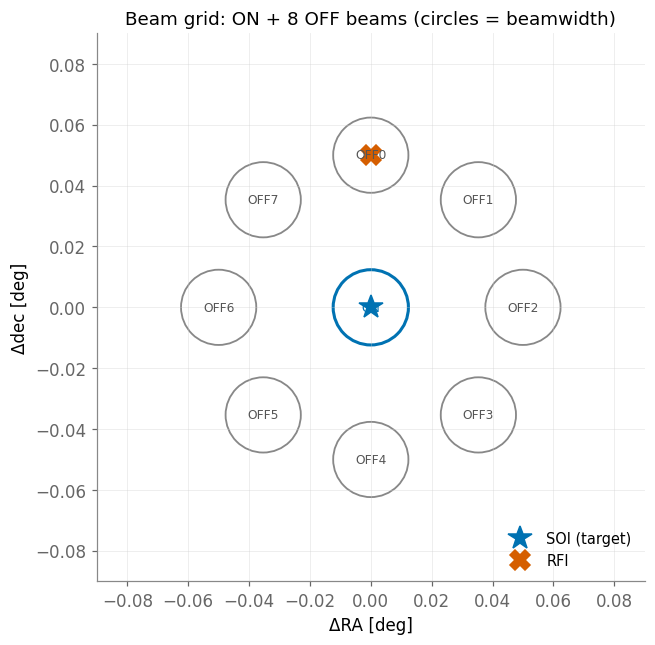

In [3]:
%matplotlib inline

beams = beam_grid(cfg, ref, ants, fc, r_off_deg=R_OFF, n_off=N_OFF)
W = np.stack([b["w"] for b in beams], axis=1)          # (A, 1+N_OFF)
B = x @ np.conj(W)                                      # (T, 1+N_OFF) all beams at once
b_on, B_off = B[:, 0], B[:, 1:]

print(f"{'beam':6s} {'d_ra':>7s} {'d_dec':>7s} {'gain@SOI':>9s} {'gain@RFI':>9s}")
for k, bm in enumerate(beams):
    print(f"{bm['name']:6s} {bm['d_ra']:+7.3f} {bm['d_dec']:+7.3f} "
          f"{beam_response(bm['w'], a_soi):9.4f} {beam_response(bm['w'], a_rfi):9.4f}")

# Sky layout of the beam grid.
fig, ax = plt.subplots(figsize=(6.2, 6))
bw = np.rad2deg(lam / 496)
for bm in beams:
    is_on = bm["name"] == "ON"
    ax.add_patch(plt.Circle((bm["d_ra"], bm["d_dec"]), bw/2,
                            fill=False, lw=2.0 if is_on else 1.2,
                            color=C_ON if is_on else C_OFF))
    ax.annotate(bm["name"], (bm["d_ra"], bm["d_dec"]), fontsize=8,
                ha="center", va="center", color=C_ON if is_on else "#555555")
ax.plot(0, 0, "*", ms=16, color=C_ON, label="SOI (target)")
ax.plot(0, R_OFF, "X", ms=13, color=C_RFI, label="RFI")
ax.set_xlim(-0.09, 0.09); ax.set_ylim(-0.09, 0.09); ax.set_aspect("equal")
ax.set_xlabel("ΔRA [deg]"); ax.set_ylabel("Δdec [deg]")
ax.set_title(f"Beam grid: ON + {N_OFF} OFF beams (circles = beamwidth)")
ax.legend(frameon=False, fontsize=9.5, loc="lower right")
fig.tight_layout()

### The 2-D beam shape

The circles above are just nominal beamwidths. The cell below computes the **actual** ON-beam power response `|wᴴa(θ)|²` over a grid of sky offsets `(ΔRA, Δdec)`. Because the array is **irregular** (random antenna positions) and projected onto the sky, the main lobe is **not circular** — typically elongated along one axis — and the sidelobes are speckled. This is why some OFF beams pick up more of the target than others: they fall on different parts of this pattern. The RFI marker shows the interferer far out in a sidelobe of the ON beam — exactly why it only leaks weakly into ON, and why the OFF beams are needed to characterise it. *(≈10 s: one steering per grid point.)*

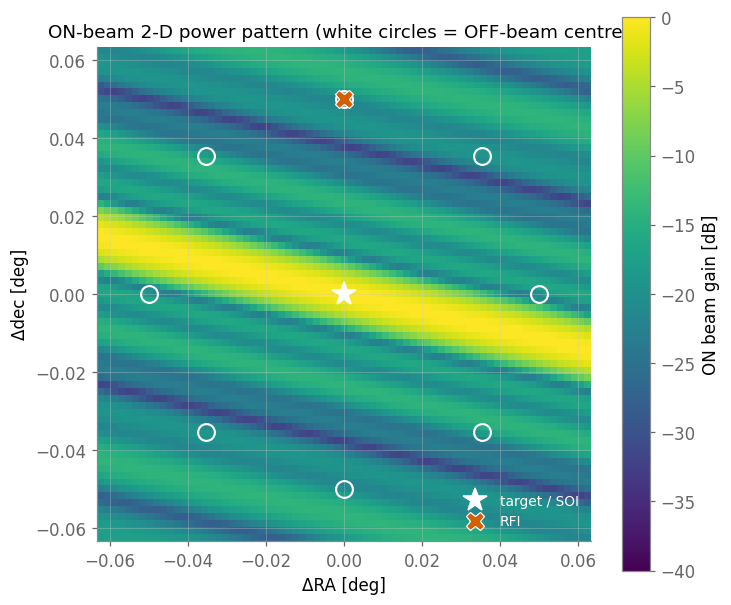

In [4]:
# 2-D ON-beam power pattern over the sky around the target.
w_on = beams[0]["w"]
n_grid = 71
half = R_OFF * 1.25                                     # show the OFF ring + margin
g_ax = np.linspace(-half, half, n_grid)
G = beam_pattern_2d(cfg, ref, ants, w_on, fc, g_ax, g_ax)
G_db = 10 * np.log10(G + 1e-9)

fig, ax = plt.subplots(figsize=(6.8, 5.8))
im = ax.pcolormesh(g_ax, g_ax, G_db, cmap="viridis", vmin=-40, vmax=0, shading="auto")
for bm in beams[1:]:                                     # OFF-beam centres
    ax.plot(bm["d_ra"], bm["d_dec"], "o", mfc="none", mec="white", ms=11, mew=1.4)
ax.plot(0, 0, "*", color="white", ms=16, label="target / SOI")
ax.plot(0, R_OFF, "X", color=C_RFI, ms=12, mec="white", mew=0.8, label="RFI")
ax.set_xlabel("ΔRA [deg]"); ax.set_ylabel("Δdec [deg]"); ax.set_aspect("equal")
ax.set_title("ON-beam 2-D power pattern (white circles = OFF-beam centres)")
ax.legend(frameon=False, fontsize=9, loc="lower right", labelcolor="white")
fig.colorbar(im, ax=ax, label="ON beam gain [dB]")
fig.tight_layout()

## Steps 3 & 4 — MR-KLT on the OFF beams, and reconstruction

The OFF beams form a `(T, N_OFF)` matrix. The interferer appears in **every** OFF beam as the *same waveform* scaled by that beam's gain toward it — i.e. a **rank-1 common mode**. Running the project's **MR-KLT** (`KLT.apply_mrklt`) on this matrix therefore puts the interference in the dominant eigenvector.

The dominant eigenvector `v` is the interference's *gain pattern across the OFF beams*; projecting the OFF beams onto it recovers the **interference waveform** `r(t)` — this is the "signal reconstructed from the OFF beams".

MR-KLT eigenvalues over the OFF beams: [2.777e+02 1.000e-01 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00
 0.000e+00]
dominant/second ratio: 2458.0x  (a clean rank-1 interference mode)


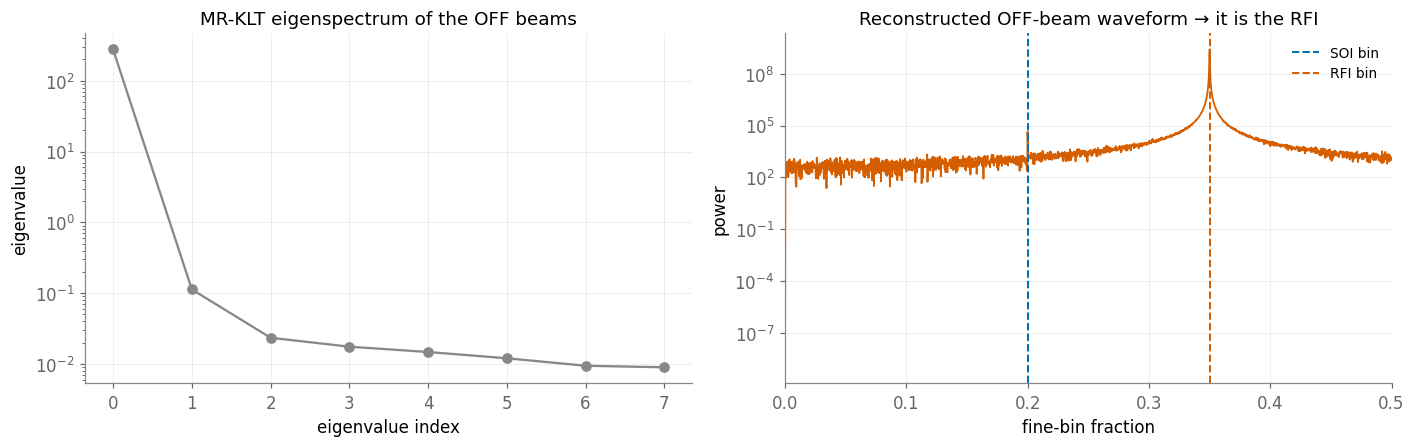

In [5]:
klt_off = KLT(logger=quiet)
klt_off.load_signal_from_array(np.ascontiguousarray(B_off))   # (T, N_OFF) = (K, N_A)
klt_off.apply_mrklt(n_eigenvectors=1)

vals_off = klt_off.get_eigenvalues()
v0 = klt_off.get_eigenvectors()[:, 0]                          # dominant OFF-beam mode
r_rfi = (B_off - B_off.mean(axis=0)) @ np.conj(v0)             # reconstructed RFI waveform (T,)

print("MR-KLT eigenvalues over the OFF beams:", np.round(vals_off, 1))
print(f"dominant/second ratio: {vals_off[0]/vals_off[1]:.1f}x  "
      f"(a clean rank-1 interference mode)")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(np.arange(len(vals_off)), vals_off, "o-", color=C_OFF)
axes[0].set_yscale("log"); axes[0].set_xlabel("eigenvalue index")
axes[0].set_ylabel("eigenvalue"); axes[0].set_title("MR-KLT eigenspectrum of the OFF beams")

P = np.abs(np.fft.fft(r_rfi - r_rfi.mean()))**2
fr = np.fft.fftfreq(len(r_rfi))
axes[1].semilogy(np.fft.fftshift(fr), np.fft.fftshift(P) + 1e-9, color=C_RFI, lw=1.2)
axes[1].axvline(SOI_BIN, color=C_ON, ls="--", lw=1.3, label="SOI bin")
axes[1].axvline(RFI_BIN, color=C_RFI, ls="--", lw=1.3, label="RFI bin")
axes[1].set_xlim(0, 0.5); axes[1].set_xlabel("fine-bin fraction")
axes[1].set_ylabel("power"); axes[1].legend(frameon=False, fontsize=9)
axes[1].set_title("Reconstructed OFF-beam waveform → it is the RFI")
fig.tight_layout()

## Step 5 — Subtract the reconstructed interference from the ON beam

The reconstruction `r(t)` carries the RFI waveform, but its **amplitude and phase in the ON beam** are unknown (the ON beam sees the RFI through a different sidelobe gain). So we fit a single complex scalar by least squares — the classic reference-channel canceller:

$$\alpha=\frac{r^{H}b_{\rm ON}}{r^{H}r},\qquad b_{\rm clean}=b_{\rm ON}-\alpha\,r$$

LS coefficient alpha = -0.0914-0.0278j
                SOI bin      RFI bin  S/I [dB]
ON before     1.463e+07    2.423e+07      -2.2
ON after      1.452e+07    2.398e+02      47.8


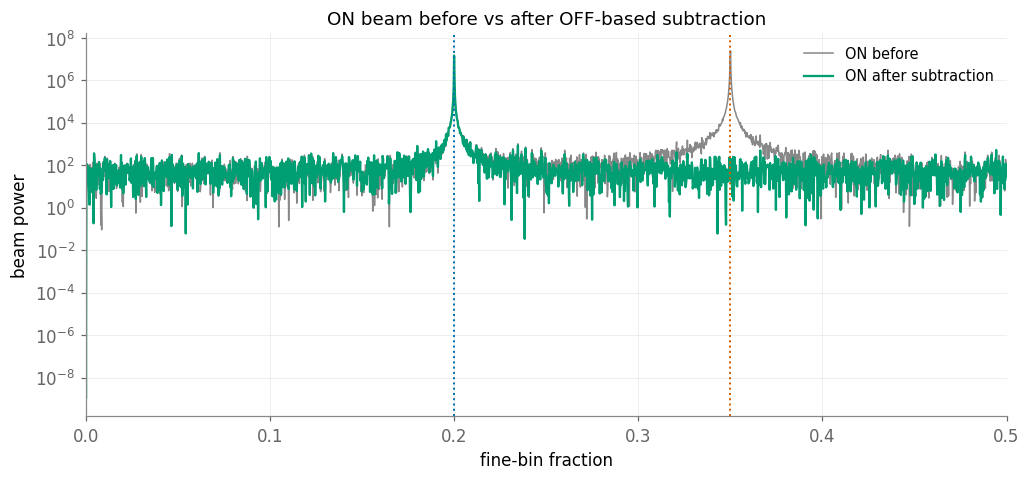

In [6]:
def bin_power(beam, frac):
    T = len(beam); P = np.abs(np.fft.fft(beam - beam.mean()))**2
    k = int(round(frac*T)) % T
    return max(P[(k+d) % T] for d in range(-2, 3))

b_clean, alpha = ls_subtract(b_on, r_rfi)
S_before, I_before = bin_power(b_on, SOI_BIN), bin_power(b_on, RFI_BIN)
S_after,  I_after  = bin_power(b_clean, SOI_BIN), bin_power(b_clean, RFI_BIN)

print(f"LS coefficient alpha = {alpha:.4f}")
print(f"{'':10s} {'SOI bin':>12s} {'RFI bin':>12s} {'S/I [dB]':>9s}")
print(f"{'ON before':10s} {S_before:12.3e} {I_before:12.3e} {10*np.log10(S_before/I_before):9.1f}")
print(f"{'ON after':10s} {S_after:12.3e} {I_after:12.3e} {10*np.log10(S_after/I_after):9.1f}")

fig, ax = plt.subplots(figsize=(9.5, 4.5))
for beam, col, lab in [(b_on, C_OFF, "ON before"), (b_clean, C_CLEAN, "ON after subtraction")]:
    P = np.abs(np.fft.fft(beam - beam.mean()))**2
    ax.semilogy(np.fft.fftshift(np.fft.fftfreq(len(beam))), np.fft.fftshift(P) + 1e-9,
                color=col, lw=1.5 if col == C_CLEAN else 1.0, label=lab)
ax.axvline(SOI_BIN, color=C_ON, ls=":", lw=1.3); ax.axvline(RFI_BIN, color=C_RFI, ls=":", lw=1.3)
ax.set_xlim(0, 0.5); ax.set_xlabel("fine-bin fraction"); ax.set_ylabel("beam power")
ax.legend(frameon=False, fontsize=9.5)
ax.set_title("ON beam before vs after OFF-based subtraction")
fig.tight_layout()

## Step 6 — C-KLT on the cleaned ON beam

Finally the C-KLT detector runs on the ON beam before and after cleaning. Before, its dominant mode reconstructs the **RFI** (a false lead); after, it reconstructs the **SOI** — the signal we actually want.

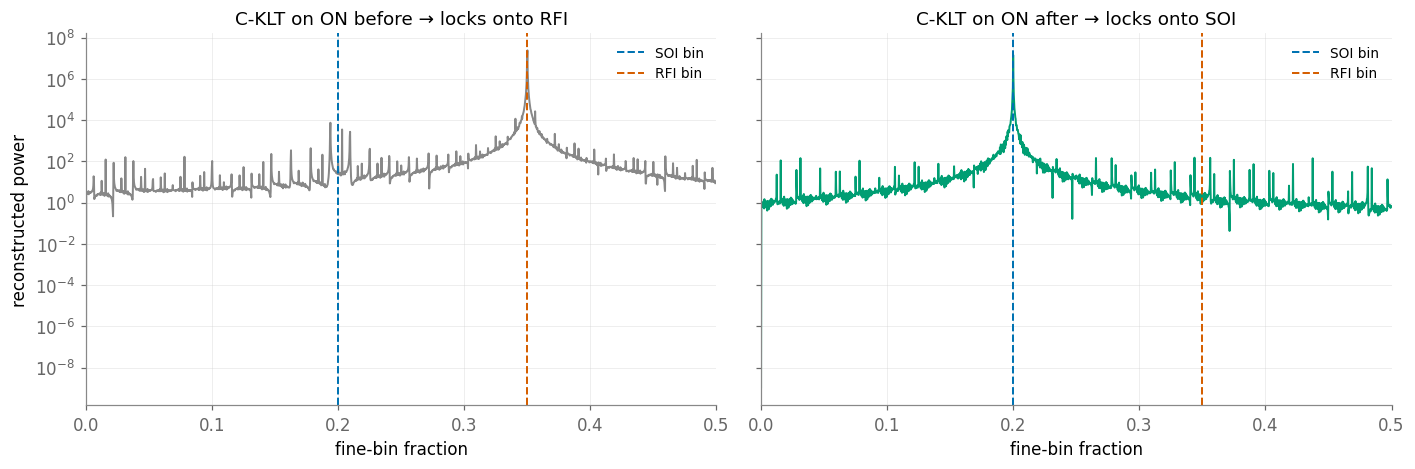

In [7]:
def cklt_peak(beam, window_size=64):
    k = KLT(logger=quiet)
    k.load_signal_from_array(np.ascontiguousarray(beam))
    k.apply_cklt(window_size=window_size, n_eigenvectors=1)
    rec = np.asarray(k.get_reconstructed_signal())
    P = np.abs(np.fft.fft(rec - rec.mean()))**2; P[0] = 0.0
    return int(np.argmax(P))/len(P), k.compute_rmt_statistics(), rec

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (lab, beam) in zip(axes, [("ON before", b_on), ("ON after", b_clean)]):
    peak, rmt, rec = cklt_peak(beam)
    P = np.fft.fftshift(np.abs(np.fft.fft(rec - rec.mean()))**2)
    fr = np.fft.fftshift(np.fft.fftfreq(len(rec)))
    ax.semilogy(fr, P + 1e-9, color=C_CLEAN if "after" in lab else C_OFF, lw=1.3)
    ax.axvline(SOI_BIN, color=C_ON, ls="--", lw=1.3, label="SOI bin")
    ax.axvline(RFI_BIN, color=C_RFI, ls="--", lw=1.3, label="RFI bin")
    locked = "SOI" if abs(peak-SOI_BIN) < 0.02 else ("RFI" if abs(peak-RFI_BIN) < 0.02 else "?")
    ax.set_xlim(0, 0.5); ax.set_xlabel("fine-bin fraction")
    ax.set_title(f"C-KLT on {lab} → locks onto {locked}")
    ax.legend(frameon=False, fontsize=9)
axes[0].set_ylabel("reconstructed power")
fig.tight_layout()

## Validation, and the OFF-ring trade-off

The scorecard below scores the pipeline against the injected truth. The sweep then varies the **OFF ring radius**, and the result is worth reading carefully:

* **RFI suppression improves as the ring moves outward** (≈28 dB at 0.02° → ≈52 dB at 0.09°). The reason is *purity of the reference*, not amplitude: further out, the OFF beams pick up less of the target, so the MR-KLT dominant mode is a cleaner estimate of the interference — and the least-squares fit rescales it anyway, so a weaker-but-purer reference cancels better.
* **SOI loss stays ≈0 at every radius** in this scenario, because the RFI here is ~225× stronger in power than the SOI: the dominant OFF-beam mode is essentially pure interference, so the subtraction has almost nothing of the target to eat.

**When self-subtraction *does* bite:** if the interferer were comparable to (or weaker than) the target, or the OFF beams overlapped the target more, the dominant OFF mode would start containing the SOI and the subtraction would cancel part of the signal we are hunting. That is the failure mode to watch on real data — it is invisible here only because of the very favourable RFI-to-SOI ratio.

Pipeline scorecard
  RFI suppression in ON :   50.0 dB
  SOI loss              :  +0.03 dB   (want ~0)
  S/I improvement       :   50.0 dB


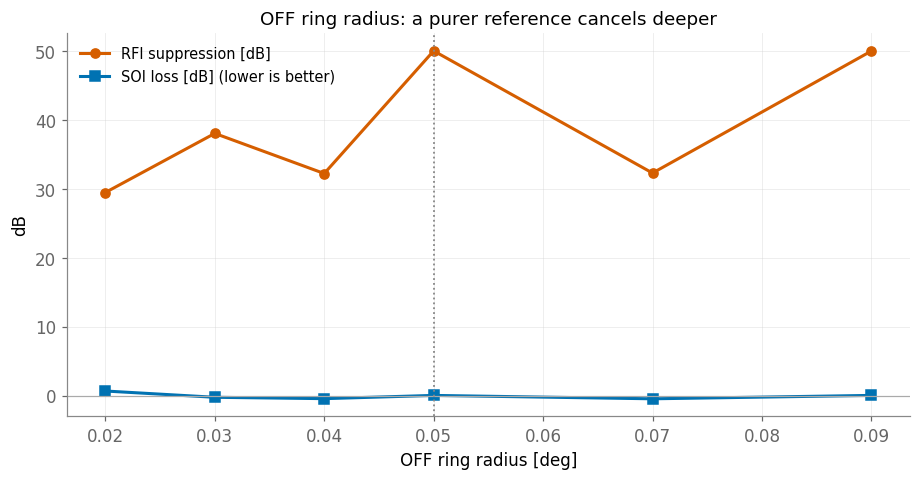

In [8]:
print("Pipeline scorecard")
print(f"  RFI suppression in ON : {10*np.log10(I_before/I_after):6.1f} dB")
print(f"  SOI loss              : {10*np.log10(S_before/S_after):+6.2f} dB   (want ~0)")
print(f"  S/I improvement       : {10*np.log10(S_after/I_after)-10*np.log10(S_before/I_before):6.1f} dB")

# How the OFF ring radius affects cancellation depth and target self-subtraction.
radii = [0.02, 0.03, 0.04, 0.05, 0.07, 0.09]
sup, loss = [], []
for r_off in radii:
    bms = beam_grid(cfg, ref, ants, fc, r_off_deg=r_off, n_off=N_OFF)
    Wr = np.stack([b["w"] for b in bms], axis=1)
    Br = x @ np.conj(Wr)
    kk = KLT(logger=quiet)
    kk.load_signal_from_array(np.ascontiguousarray(Br[:, 1:]))
    kk.apply_mrklt(n_eigenvectors=1)
    vv = kk.get_eigenvectors()[:, 0]
    rr = (Br[:, 1:] - Br[:, 1:].mean(axis=0)) @ np.conj(vv)
    bc, _ = ls_subtract(Br[:, 0], rr)
    sup.append(10*np.log10(bin_power(Br[:, 0], RFI_BIN)/bin_power(bc, RFI_BIN)))
    loss.append(10*np.log10(bin_power(Br[:, 0], SOI_BIN)/bin_power(bc, SOI_BIN)))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(radii, sup, "o-", color=C_RFI, lw=2, label="RFI suppression [dB]")
ax.plot(radii, loss, "s-", color=C_ON, lw=2, label="SOI loss [dB] (lower is better)")
ax.axhline(0, color="#AAAAAA", lw=0.8)
ax.axvline(R_OFF, color="#888888", ls=":", lw=1.2)
ax.set_xlabel("OFF ring radius [deg]"); ax.set_ylabel("dB")
ax.set_title("OFF ring radius: a purer reference cancels deeper")
ax.legend(frameon=False, fontsize=9.5)
fig.tight_layout()

## 7. Computational cost (analysis only, no signal generation)

To compare with other methods in the literature, the fair, hardware-independent metric is the **operation count (FLOPs)** of each stage. We report that alongside a wall-clock, with one caveat: the wall-clock of this *reference Python implementation* is **overhead-bound** (KLT-object creation, framework), so it overstates the intrinsic cost — an optimised C/GPU implementation would approach the FLOP-limited time. We therefore time the **arithmetic-only** version of the pipeline (same math, no framework objects) for the breakdown and scaling, and show the framework-inclusive number for context.

Leading complexity (`A` antennas, `B` beams, `T` samples, `W` C-KLT window, `K=T/W` windows):

| stage | complexity | note |
|---|---|---|
| beamform `x Wᴴ` | `O(T·A·B)` | the **only** antenna-dependent stage |
| MR-KLT on OFF + recon | `O(T·B² + B³)` | `B` = number of beams (small) |
| LS subtraction | `O(T)` | negligible |
| C-KLT on ON beam | `O(T·W + W³)` | window covariance + eig |

Because the heavy stages act on **beams and windows, not antennas**, the total is expected to be **linear in the sample count `T`** and **nearly independent of the antenna count `A`** — the scaling cell checks this empirically.

config: A=64 antennas | B=9 beams | T=4096 samples | W=64 | K=64 windows
stage           time [µs]    %    MFLOP   complexity
beamform            673.4   33    18.87        T·A·B
MR-KLT (OFF)        582.3   29     2.95      T·B²+B³
LS subtract          20.1    1     0.07            T
C-KLT (ON)          753.1   37     6.29       T·W+W³
TOTAL              2028.9  100    28.19

intrinsic : 2.03 ms/channel  →  65 ms for 32 channels  (28.2 MFLOP/ch, 13.9 GFLOP/s effective)
reference : 5.8 ms/channel with the KLT-object pipeline (Python-overhead-bound)


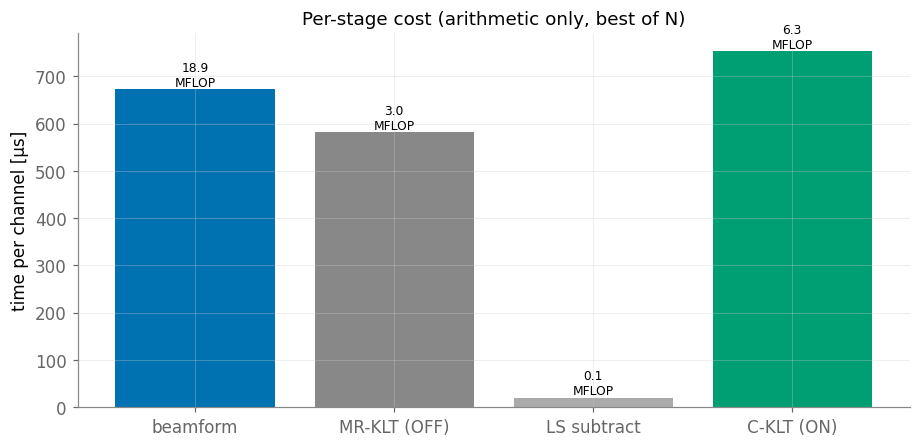

In [9]:
import time, gc

Wk = 64                                    # C-KLT window (as in Step 6)
A, B_, T = cfg.num_antennas, W.shape[1], cfg.n_time
K = T // Wk

# Arithmetic-only mirror of process_channel: same maths, no KLT objects, so the
# timing reflects the intrinsic linear-algebra cost rather than Python overhead.
def _arith(x_ch, Wb, w_win, timed=False):
    t = {}
    s = time.perf_counter(); M = x_ch @ np.conj(Wb); bon, Boff = M[:, 0], M[:, 1:]
    t["beamform"] = time.perf_counter() - s
    s = time.perf_counter()
    _, Vo = np.linalg.eigh(np.cov(Boff, rowvar=False)); v0 = Vo[:, -1]
    r = (Boff - Boff.mean(0)) @ np.conj(v0)
    t["MR-KLT (OFF)"] = time.perf_counter() - s
    s = time.perf_counter(); al = np.vdot(r, bon) / np.vdot(r, r); bc = bon - al * r
    t["LS subtract"] = time.perf_counter() - s
    s = time.perf_counter()
    Kk = len(bc) // w_win; Mw = bc[:Kk * w_win].reshape(Kk, w_win)
    _, wc = np.linalg.eigh(np.cov(Mw, rowvar=False))
    cm = Mw.mean(0); co = (Mw - cm) @ wc[:, -1:].conj(); (co @ wc[:, -1:].T + cm).ravel()
    t["C-KLT (ON)"] = time.perf_counter() - s
    return t if timed else bc

def _best_stages(reps=40):
    _arith(x, W, Wk, timed=True); agg = {}; gc.disable()
    for _ in range(reps):
        for k, v in _arith(x, W, Wk, timed=True).items():
            agg.setdefault(k, []).append(v)
    gc.enable(); return {k: min(v) for k, v in agg.items()}

tmin = _best_stages()
flop = {"beamform": 8*T*A*B_, "MR-KLT (OFF)": 8*(T*B_*B_ + B_**3 + T*B_),
        "LS subtract": 8*2*T, "C-KLT (ON)": 8*(K*Wk*Wk + Wk**3 + T*Wk)}
comp = {"beamform": "T·A·B", "MR-KLT (OFF)": "T·B²+B³", "LS subtract": "T", "C-KLT (ON)": "T·W+W³"}
stages = list(flop); tot_t, tot_f = sum(tmin.values()), sum(flop.values())

print(f"config: A={A} antennas | B={B_} beams | T={T} samples | W={Wk} | K={K} windows")
print(f"{'stage':14s}{'time [µs]':>11s}{'%':>5s}{'MFLOP':>9s}{'complexity':>13s}")
for k in stages:
    print(f"{k:14s}{tmin[k]*1e6:11.1f}{100*tmin[k]/tot_t:5.0f}{flop[k]/1e6:9.2f}{comp[k]:>13s}")
print(f"{'TOTAL':14s}{tot_t*1e6:11.1f}{100:5.0f}{tot_f/1e6:9.2f}")
print(f"\nintrinsic : {tot_t*1e3:.2f} ms/channel  →  {tot_t*cfg.num_chans*1e3:.0f} ms for {cfg.num_chans} channels"
      f"  ({tot_f/1e6:.1f} MFLOP/ch, {tot_f/tot_t/1e9:.1f} GFLOP/s effective)")
tref = min(process_channel(x, W, logger=quiet, window_size=Wk, timed=True)["times"]["total"] for _ in range(10))
print(f"reference : {tref*1e3:.1f} ms/channel with the KLT-object pipeline (Python-overhead-bound)")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(stages, [tmin[k]*1e6 for k in stages], color=[C_ON, C_OFF, "#AAAAAA", C_CLEAN])
for i, k in enumerate(stages):
    ax.annotate(f"{flop[k]/1e6:.1f}\nMFLOP", (i, tmin[k]*1e6), ha="center", va="bottom", fontsize=8)
ax.set_ylabel("time per channel [µs]")
ax.set_title("Per-stage cost (arithmetic only, best of N)")
fig.tight_layout()

cost ∝ T^0.57 · A^0.08  →  linear in samples, ~independent of antenna count
(WSL/CPU timing is noisy; the exponents confirm the FLOP model's leading terms)


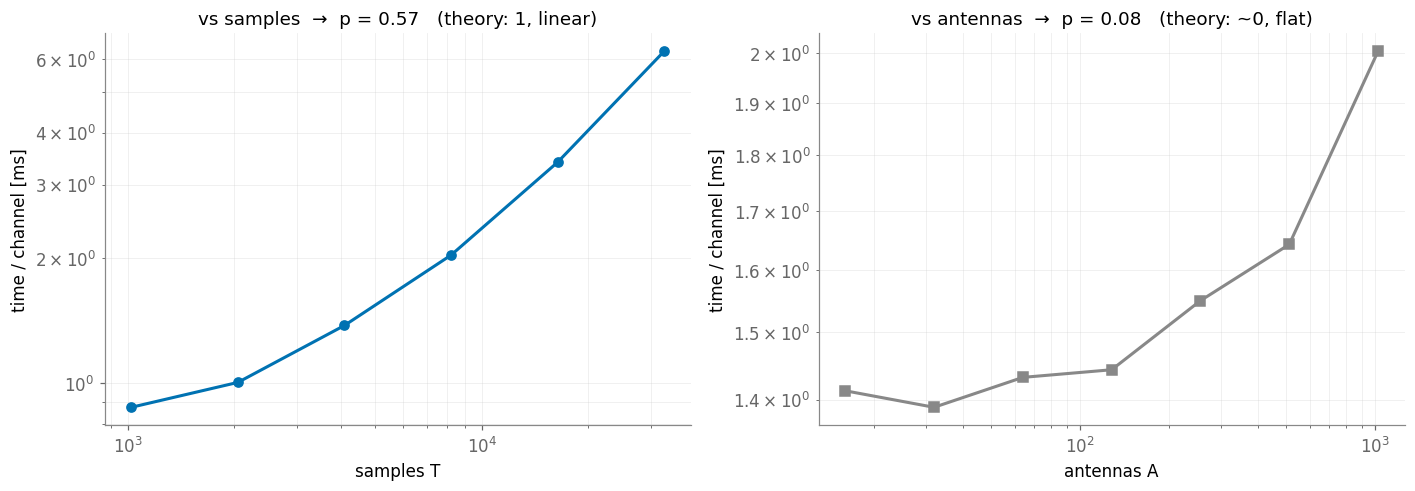

In [10]:
# Empirical scaling of the intrinsic cost, on random data (shape-only timing).
rng = np.random.default_rng(0)
def _rand(T_, A_):
    xr = (rng.standard_normal((T_, A_)) + 1j*rng.standard_normal((T_, A_))).astype(np.complex64)
    Wr = (rng.standard_normal((A_, B_)) + 1j*rng.standard_normal((A_, B_))).astype(np.complex64)
    return xr, Wr
def _best(T_, A_, reps=20):
    xr, Wr = _rand(T_, A_); _arith(xr, Wr, Wk); gc.disable(); out = []
    for _ in range(reps):
        s = time.perf_counter(); _arith(xr, Wr, Wk); out.append(time.perf_counter() - s)
    gc.enable(); return min(out)

Ts = [1024, 2048, 4096, 8192, 16384, 32768]
As = [16, 32, 64, 128, 256, 512, 1024]
tT = np.array([_best(T_, 64) for T_ in Ts])
tA = np.array([_best(4096, A_) for A_ in As])
pT = np.polyfit(np.log(Ts), np.log(tT), 1)[0]
pA = np.polyfit(np.log(As), np.log(tA), 1)[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].loglog(Ts, tT*1e3, "o-", color=C_ON, lw=2)
axes[0].set_xlabel("samples T"); axes[0].set_ylabel("time / channel [ms]")
axes[0].set_title(f"vs samples  →  p = {pT:.2f}   (theory: 1, linear)")
axes[1].loglog(As, tA*1e3, "s-", color=C_OFF, lw=2)
axes[1].set_xlabel("antennas A"); axes[1].set_ylabel("time / channel [ms]")
axes[1].set_title(f"vs antennas  →  p = {pA:.2f}   (theory: ~0, flat)")
for a in axes:
    a.grid(True, which="both", alpha=0.3)
fig.tight_layout()

print(f"cost ∝ T^{pT:.2f} · A^{pA:.2f}  →  linear in samples, ~independent of antenna count")
print("(WSL/CPU timing is noisy; the exponents confirm the FLOP model's leading terms)")

## 8. Playground — try different physical situations

Everything above is fixed to one scenario. This section exposes **every knob in one place**: edit the `PARAMS` block below (array size, fine channel, OFF ring, C-KLT window, and the list of sources given as **offsets from the target**), then re-run the next cell. `run_experiment(...)` builds the geometry, simulates the cube, runs the full ON/OFF → MR-KLT → subtract → C-KLT pipeline, and `experiment_report(...)` prints the diagnostics plus the before/after spectrum and the OFF eigenspectrum.

**Automatic RFI counting.** With `n_off_modes="auto"` the pipeline no longer needs to be told how many interferers there are — it estimates them with **Kritchman & Nadler** (`seti_klt.KN_rankEst`) applied to the OFF-beam MR-KLT. Two subtleties are handled:
* the OFF beams overlap (shared antennas) so their **noise is coloured**; K&N (which assumes white noise) would over-count, so we feed it the *whitened* eigenvalues (generalised eigenvalues against the known beam-noise covariance `Wᴴ_off W_off`);
* the **SOI leaks weakly into the OFF beams** and shows up as an extra detected mode — removing it would self-subtract the signal, so the mode whose OFF-beam signature matches the target direction is excluded, and only the genuine RFI are removed (each with its own least-squares coefficient).

The report shows *modes detected* → *RFI removed* against the true injected count. Things worth probing:
* move the interferer **off** the OFF ring → weaker reference, worse cancellation;
* make the RFI **comparable to the SOI** in level, or **add several interferers** → watch `n_off_modes="auto"` track the count and the multi-reference subtraction remove them all;
* shrink `off_radius_deg` toward the beamwidth → the target leaks more into the OFF beams (larger SOI-leakage mode);
* tighten/loosen `kn_alpha` → stricter/looser detection threshold.

In [11]:
# ======================= PARAMETER PANEL — edit me =======================
# Sources are given as OFFSETS from the target pointing (degrees). Roles:
#   "signal"     = the SOI you want to recover (usually at the target, 0,0)
#   "interferer" = RFI you want to remove
SOURCES = [
    dict(name="SOI", role="signal",     d_ra=0.00, d_dec=0.00, bin=0.20, level=1.0,  drift=0.0),
    dict(name="RFI", role="interferer", d_ra=0.00, d_dec=0.05, bin=0.35, level=15.0, drift=0.0),
]

PARAMS = dict(
    sources=SOURCES,
    # --- array / band ---
    num_antennas=64,        # number of antennas
    array_radius_m=1000.0,  # array footprint radius [m]  → sets beamwidth ~ λ/(2·radius)
    num_branches=16384,     # PFB branches → fine-channel width = sample_rate/num_branches
    num_chans=32,           # coarse channels simulated
    n_time=4096,            # time samples per channel (beam length T)
    noise_std=1.0,          # per-antenna thermal noise
    seed=1,                 # RNG seed (array layout + noise)
    channel=8,              # coarse channel to analyse
    # --- ON/OFF beam grid ---
    off_radius_deg=0.05,    # radius of the OFF ring [deg]
    n_off=8,                # number of OFF beams on the ring
    # --- interference count & KLT ---
    n_off_modes="auto",     # "auto" → Kritchman & Nadler counts the RFI from the OFF
                            #          beams (whitened for the coloured beam noise) and
                            #          excludes the SOI-leakage mode; or set an int to fix it
    kn_alpha=0.5,           # K&N false-alarm level per test [%] (stress-test sweet spot ≈0.5)
    cklt_window=64,         # C-KLT window W
)
# =========================================================================

array 64 ant, 1000 m | channel 8 (183 kHz) | OFF ring 0.05 deg x 8

source  role          d_ra  d_dec   bin    g@ON g@OFFmax suppr[dB]
SOI     signal      +0.000 +0.000  0.20  0.9955   0.0207       0.0
RFI     interferer  +0.000 +0.050  0.35  0.0112   0.9822      50.0

S/I in ON : -2.2 dB  ->  +47.8 dB   (RFI suppressed 50.0 dB, SOI loss +0.03 dB)
K&N on OFF : 2 spatial modes detected (incl. SOI leakage → excluded) → 1 RFI removed  (true interferers: 1)
MR-KLT OFF : dominant/2nd = 2458x | LS alpha = [-0.091-0.028j]
C-KLT on cleaned ON locks onto: SOI (peak bin 0.200)
cost       : 62.6 ms/channel (KLT-object pipeline)


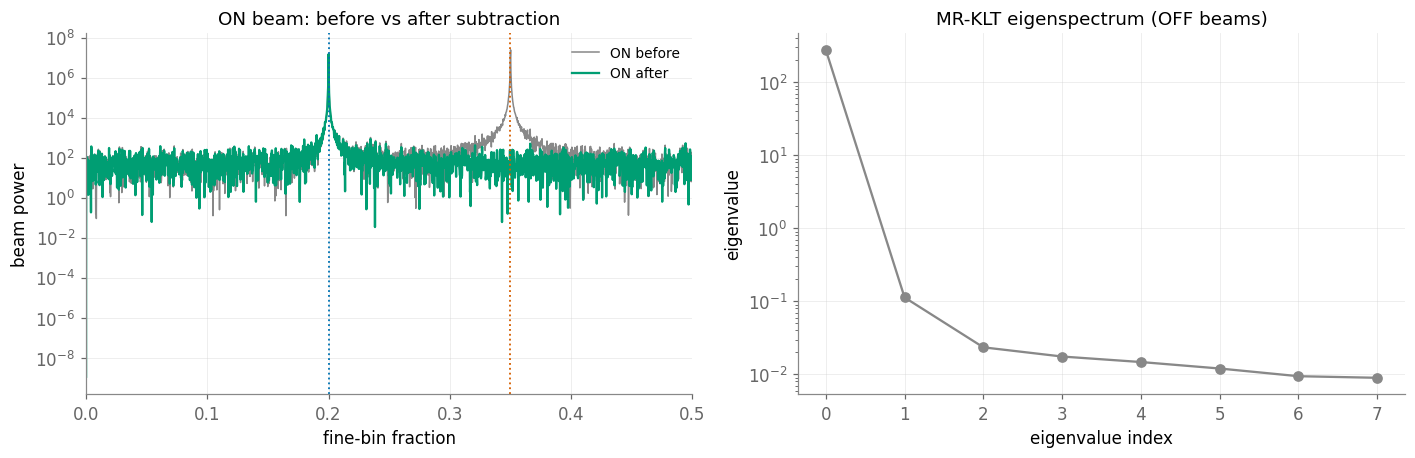

In [12]:
# Run the whole pipeline with the parameters above and print/plot diagnostics.
res = run_experiment(**PARAMS, logger=quiet)
experiment_report(res, plot=True)

# `res` also holds the raw products if you want to dig further, e.g.:
#   res["b_on"], res["b_clean"]        -- ON beam before / after subtraction
#   res["sources"]                     -- per-source gains and before/after power
#   res["off_eigenvalues"], res["alpha"], res["times"]

## 9. Stress-test (A) — does the auto pipeline hold up in general?

The playground checks one scenario at a time; this section checks **robustness across many randomised scenarios**. For each configuration, `stress_point(...)` runs `n_trials` realisations with fresh noise, **random interferer directions** (random azimuth on the OFF ring) and random fine bins, and scores each against the injected truth. We track:

* **count accuracy** — fraction of trials where K&N removed *exactly* the true number of RFI;
* **SOI loss** — how much of the signal the subtraction eats (want ≈ 0);

and sweep the four knobs that matter for generality:
1. **RFI level** (strong → down toward the noise): K&N *should* stop detecting when the RFI sinks into the noise — that is correct behaviour, not a bug;
2. **number of interferers** (1→4): does the count track, and does the multi-reference subtraction keep up;
3. **OFF-ring radius**: too small and the SOI leaks into the OFF beams (the exclusion has to work harder);
4. **`kn_alpha`**: the detection threshold — looser α over-detects, tighter α misses weak RFI.

*(This cell runs a few hundred pipeline evaluations on a single channel — ~1 min.)*

RFI level        done  (7 points × 15 trials)
# interferers    done  (4 points × 15 trials)
OFF radius [deg] done  (5 points × 15 trials)


/mnt/c/Users/gigig/Documents/University/SETI/codes/src/seti_klt/kritchman_nadler.py:280: UserWarning: KN_s_Wishart: alpha=2.0 is outside the valid range for this asymptotic approximation (beta=2 requires alpha < 1.9894). The original paper states this formula holds only for alpha << 1. The result will be NaN (matching the original MATLAB's behaviour under a fractional power of a negative number) rather than a meaningful threshold.
  s_Wishart = KN_s_Wishart(alpha, beta)
/mnt/c/Users/gigig/Documents/University/SETI/codes/src/seti_klt/kritchman_nadler.py:99: RuntimeWarning: invalid value encountered in scalar power
  return float((-3.0 / 4.0 * np.log(16.0 * np.pi * alpha / 100.0)) ** (2.0 / 3.0))
/mnt/c/Users/gigig/Documents/University/SETI/codes/src/seti_klt/kritchman_nadler.py:280: UserWarning: KN_s_Wishart: alpha=5.0 is outside the valid range for this asymptotic approximation (beta=2 requires alpha < 1.9894). The original paper states this formula holds only for alpha << 1. The resul

K&N alpha [%]    done  (5 points × 15 trials)


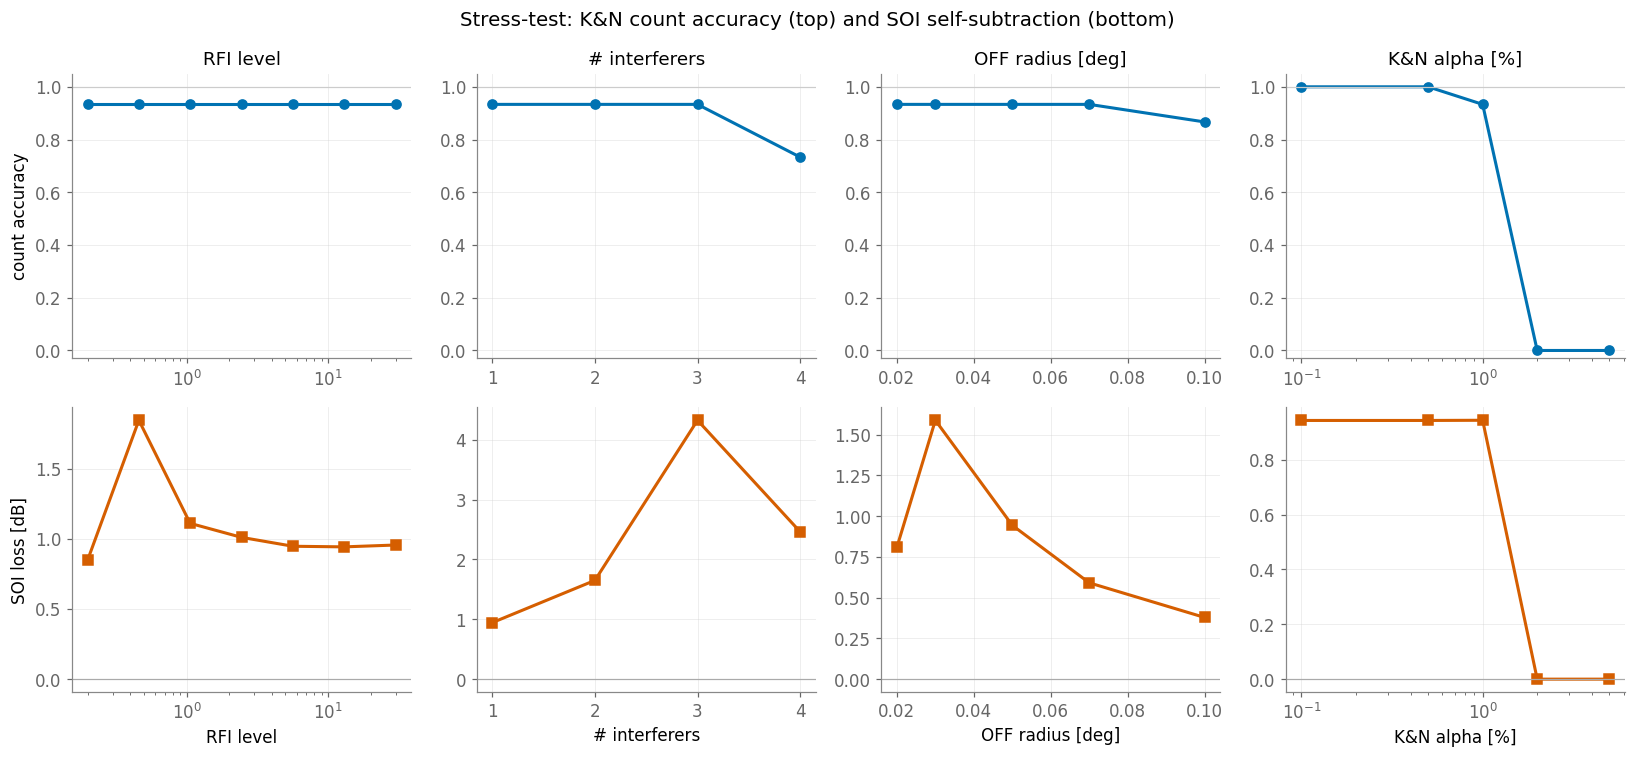

In [13]:
# Fixed array/channel knobs (single channel for speed); sweeps randomise the rest.
base = dict(num_antennas=64, array_radius_m=1000.0, num_branches=16384,
            num_chans=1, channel=0, n_time=4096, noise_std=1.0, n_off=8, cklt_window=64)
NT = 15   # realisations averaged per point

# (label, x-values, kwargs that vary per point)
sweeps = {
    "RFI level":       (np.round(np.geomspace(0.2, 30.0, 7), 2),
                        lambda v: dict(n_rfi=1, rfi_level=float(v))),
    "# interferers":   (np.array([1, 2, 3, 4]),
                        lambda v: dict(n_rfi=int(v), rfi_level=15.0)),
    "OFF radius [deg]":(np.array([0.02, 0.03, 0.05, 0.07, 0.10]),
                        lambda v: dict(n_rfi=1, rfi_level=15.0, off_radius_deg=float(v))),
    "K&N alpha [%]":   (np.array([0.1, 0.5, 1.0, 2.0, 5.0]),
                        lambda v: dict(n_rfi=1, rfi_level=15.0, kn_alpha=float(v))),
}

results = {}
for name, (vals, mk) in sweeps.items():
    rows = [stress_point(n_trials=NT, seed0=7, logger=quiet, **mk(v), **base) for v in vals]
    results[name] = (vals, rows)
    print(f"{name:16s} done  ({len(vals)} points × {NT} trials)")

# --- plot: count accuracy (row 1) and SOI loss (row 2) vs each swept knob ---
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for j, (name, (vals, rows)) in enumerate(results.items()):
    acc = [r["count_acc"] for r in rows]
    loss = [r["soi_loss"] for r in rows]
    logx = name in ("RFI level", "K&N alpha [%]")
    a0, a1 = axes[0, j], axes[1, j]
    (a0.semilogx if logx else a0.plot)(vals, acc, "o-", color=C_ON, lw=2)
    a0.set_ylim(-0.03, 1.05); a0.set_title(name); a0.axhline(1.0, color="#CCC", lw=0.8)
    (a1.semilogx if logx else a1.plot)(vals, loss, "s-", color=C_RFI, lw=2)
    a1.axhline(0, color="#AAAAAA", lw=0.8)
    a1.set_xlabel(name)
axes[0, 0].set_ylabel("count accuracy")
axes[1, 0].set_ylabel("SOI loss [dB]")
fig.suptitle("Stress-test: K&N count accuracy (top) and SOI self-subtraction (bottom)", fontsize=13)
fig.tight_layout()

### What the stress-test says (and where the method breaks)

* **RFI level** — K&N keeps counting reliably down to weak interferers, and only loses them once they sink into the noise (correct behaviour: you cannot remove what you cannot see). SOI loss stays ~1 dB throughout.
* **Number of interferers** — solid for 1–3, but degrades at **4 RFI on 8 OFF beams** (count accuracy drops, SOI loss climbs). Rule of thumb: keep `n_off` comfortably larger than the expected RFI count.
* **OFF-ring radius** — the clearest generality lever: a **wider ring reduces SOI loss** (the SOI leaks less into the OFF beams), confirming that good geometry, not the exclusion patch, is the real fix. Too tight a ring makes the exclusion work hard.
* **`kn_alpha`** — the detection threshold is the most sensitive knob: **≈0.5 %** is the sweet spot (perfect count); looser values (≥2 %) over-detect and the count collapses. The default is set to 0.5.

Bottom line for "does it generalise": within simulation it is robust as long as (i) `n_off` > RFI count, (ii) the OFF ring is a few beamwidths out, and (iii) `kn_alpha` is tight. The residual ~7 % miss rate comes from random geometries where an interferer lands between OFF beams. The remaining gap to *real* data is the white-noise assumption behind the whitening — that is task **(B)**, the adaptive (data-estimated) noise covariance.